# Projet 5: Classification des mauvaises herbes
**Classes :** Chinee apple, Lantana et Snake weed.

1. Travail demandé : k-NN, Softmax linéaire et CNN sur 900 images.
2. Expérimentations complémentaires : 3000 images et modèles pré-entraînés.
3. Sauvegarde et téléchargement des modèles.

Rédigé par:
- ABOULHODA Saad
- KADADE MAHAMADOU Bassirou
- OUMANSOUR Abdelatif

## Préparation


In [5]:
from pathlib import Path
import sys, os, shutil, zipfile, subprocess, importlib.metadata as metadata
from datetime import datetime

if not Path("deepweeds_utils.py").exists():
    from google.colab import files
    fichiers = files.upload()
    archive = next(name for name in fichiers if name.endswith(".zip"))
    with zipfile.ZipFile(archive) as fichier:
        fichier.extractall(".")

### Installation

In [6]:
TF_PACKAGE = "tensorflow" if sys.platform.startswith("linux") and shutil.which("nvidia-smi") else "tensorflow-cpu"
paquets = {"numpy": "2.3.5", "scipy": "1.17.0", "scikit-learn": "1.8.0",
           TF_PACKAGE: "2.21.0", "keras": "3.15.1", "torch": "2.14.1",
           "torchvision": "0.29.1", "pillow": "13.0.0"}
dependances = [f"{p}[and-cuda]=={v}" if p == "tensorflow" else f"{p}=={v}"
               for p, v in paquets.items()]
subprocess.check_call([sys.executable, "-m", "pip", "install", *dependances,
                       "pandas", "matplotlib", "tabulate", "joblib"]);

In [7]:
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["XFORMERS_DISABLED"] = "1"
os.environ["TF_DATA_AUTOTUNE_MAX_PARALLELISM"] = "2"

import hashlib, time, gc, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import torch
import joblib
from PIL import Image
from torchvision import transforms
from IPython.display import display, FileLink
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, StratifiedKFold, StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.metrics import accuracy_score
from scipy.stats import binomtest, norm
get_ipython().run_line_magic("matplotlib", "inline")

### Paramètres
Les réglages sont choisis sur validation ; les images test servent à l'évaluation finale.

In [8]:
N_900, N_3000 = 300, 1000       # Images par classe.
PLIS, REPETITIONS = 5, 2
EPOCHS_CNN, EPOCHS_SOFTMAX = 300, 100
EPOCHS_TETE, EPOCHS_FINETUNING = 40, 20
SEEDS = [40, 41, 42, 43, 44]
CLASSES = ["Chinee apple", "Lantana", "Snake weed"]
SHORT = ["CA", "LA", "SW"]

ROOT = Path("deepweeds_execution").resolve()
RAW = ROOT / "images"
EXPORT = ROOT / ("modeles_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
MODELS, SHARED, RESULTS = [EXPORT / name for name in ["models", "shared", "results"]]
RESSOURCES = Path("ressources")
for directory in [RAW, MODELS, SHARED, RESULTS]:
    directory.mkdir(parents=True, exist_ok=True)

tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.experimental.enable_op_determinism()
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)
torch.set_num_threads(2)

In [9]:
from deepweeds_utils import (initialiser, REGISTRY, RECORDS, HISTORIES, tableau, mesures,
    matrices, resume, ecrire_json, empreinte, telecharger, dossier_modele,
    sauvegarder_tf, sauvegarder_knn, enregistrer)

initialiser(EXPORT, CLASSES)
ecrire_json(EXPORT / "versions.json", {p: metadata.version(p) for p in paquets})

### Données
Les CSV contiennent uniquement les noms et les étiquettes des deux échantillons du rapport : 300 images par classe tirées aléatoirement (seed 42), puis 1000 par classe dans l'ordre TFDS.
Les JPEG originaux sont téléchargés et décodés ci-dessous. Aucune caractéristique ni prédiction enregistrée n'est utilisée.

In [10]:
archive = telecharger("https://zenodo.org/records/7939060/files/images.zip?download=1",
                       ROOT / "images.zip", md5="b7b30f96d466fba86016aa5a26606e0f")
if len(list(RAW.glob("*.jpg"))) != 17509:
    with zipfile.ZipFile(archive) as fichier:
        for name in fichier.namelist():
            if name.lower().endswith(".jpg"):
                with fichier.open(name) as source, (RAW / Path(name).name).open("wb") as target:
                    shutil.copyfileobj(source, target)

meta900 = pd.read_csv(RESSOURCES / "images900.csv")
meta3000 = pd.read_csv(RESSOURCES / "images3000.csv")
labels_path = telecharger("https://raw.githubusercontent.com/AlexOlsen/DeepWeeds/master/labels/labels.csv", ROOT / "labels.csv")
labels = pd.read_csv(labels_path).set_index("Filename")["Label"].map({0: 0, 1: 1, 7: 2})
for meta in [meta900, meta3000]:
    assert np.array_equal(labels.loc[meta.filename].to_numpy(), meta.label.to_numpy())

Téléchargé : images.zip
Téléchargé : labels.csv


In [11]:
def lire_images(filenames):
    return np.asarray([tf.io.decode_image(tf.io.read_file(str(RAW / name)), channels=3,
                        expand_animations=False).numpy() for name in filenames], dtype=np.uint8)

images = lire_images(meta3000.filename)
image_hash = hashlib.sha256(memoryview(images)).hexdigest()
y = meta3000.label.to_numpy()
names = meta3000.filename.to_numpy()
images900 = lire_images(meta900.filename)
y900 = meta900.label.to_numpy()
names900 = meta900.filename.to_numpy()
x900 = tf.image.resize(images900, (32, 32)).numpy() / 255.
x_hist = tf.image.resize(images, (32, 32)).numpy() / 255.
del images900
assert np.array_equal(np.bincount(y900), [N_900] * 3)
assert np.array_equal(np.bincount(y), [N_3000] * 3)
print("900 images :", np.bincount(y900), "— 3000 images :", np.bincount(y))

900 images : [300 300 300] — 3000 images : [1000 1000 1000]


### Découpage des données
Chaque comparaison utilise les mêmes indices pour tous ses modèles. Le protocole principal conserve 540 images train, 180 validation et 180 test par essai.

In [12]:
def split_simple(indices, labels, seed=42):
    tv, test = train_test_split(indices, test_size=.2, random_state=seed, stratify=labels[indices])
    train, val = train_test_split(tv, test_size=.25, random_state=seed, stratify=labels[tv])
    return {"train": train, "val": val, "test": test}

hist_split = split_simple(np.arange(len(y)), y)
small_idx = np.sort(np.concatenate([np.flatnonzero(y == c)[:N_900] for c in range(3)]))
small_split = split_simple(small_idx, y)
core_splits = []
cv = RepeatedStratifiedKFold(n_splits=PLIS, n_repeats=REPETITIONS, random_state=42)
for fold, (tv, test) in enumerate(cv.split(x900, y900)):
    train, val = train_test_split(tv, test_size=.25, random_state=42 + fold, stratify=y900[tv])
    core_splits.append({"train": train, "val": val, "test": test, "seed": 42 + fold})

tableau([{"Ensemble": k, "Pli à 900 images": len(core_splits[0][k]),
          "Groupe à 3000 images": len(hist_split[k])} for k in ["train", "val", "test"]]);

| Ensemble   | Pli à 900 images   | Groupe à 3000 images   |
|:-----------|:-------------------|:-----------------------|
| train      | 540                | 1800                   |
| val        | 180                | 600                    |
| test       | 180                | 600                    |

In [13]:
np.savez_compressed(RESULTS / "splits.npz", y=y, filenames=names, y900=y900, filenames900=names900,
                     **hist_split, **{"small_" + k: v for k, v in small_split.items()})
ecrire_json(RESULTS / "core_splits.json", [{k: v.tolist() if isinstance(v, np.ndarray) else v
              for k, v in split.items()} for split in core_splits])

# 1. Travail demandé - 900 images
## 1.1. Modèles
- **k-NN :** pixels aplatis ; K = 1, 3, 5, 7, 9 ; distances L1 et L2.
- **Softmax :** Flatten → Dense(3), sans couche cachée.
- **CNN :** Conv32 → Pool → Conv64 → Pool → Flatten → Dense64 → Dense3.

In [14]:
def modele_pixels(kind, seed=42, augmentation=True, aug_seed=None, explicite=True):
    L = tf.keras.layers
    def init(s):
        return {"kernel_initializer": tf.keras.initializers.GlorotUniform(seed=s)} if explicite else {}
    if kind == "softmax":
        return tf.keras.Sequential([L.Input((32, 32, 3)), L.Flatten(),
                                    L.Dense(3, activation="softmax", **init(seed))])
    layers = [L.Input((32, 32, 3))]
    if augmentation:
        a = seed + 11 if aug_seed is None else aug_seed
        a = a if explicite else None
        seeds = [a + i if a is not None else None for i in range(6)]
        layers += [L.RandomFlip("horizontal_and_vertical", seed=seeds[0]),
                   L.RandomRotation(.25, seed=seeds[1]), L.RandomZoom(.15, seed=seeds[2]),
                   L.RandomTranslation(.1, .1, seed=seeds[3]), L.RandomContrast(.2, seed=seeds[4]),
                   L.RandomBrightness(.15, value_range=(0, 1), seed=seeds[5])]
    layers += [L.Conv2D(32, 3, activation="relu", **init(seed)), L.MaxPooling2D(),
               L.Conv2D(64, 3, activation="relu", **init(seed + 1)), L.MaxPooling2D(), L.Flatten(),
               L.Dense(64, activation="relu", **init(seed + 2)), L.Dense(3, activation="softmax", **init(seed + 3))]
    return tf.keras.Sequential(layers)

## 1.2. Entraînement
Lots de 32 ; meilleur checkpoint selon la perte de validation. Softmax utilise Adam à 0,001 et un arrêt anticipé. Le CNN utilise une décroissance cosinus sur 300 époques.

In [15]:
def dataset(x, y, seed=42, melanger=False, batch=32, pool=1):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if melanger:
        ds = ds.shuffle(len(y), seed=seed, reshuffle_each_iteration=True)
    options = tf.data.Options(); options.threading.private_threadpool_size = pool
    return ds.batch(batch).with_options(options).prefetch(1)

def probabilites(model, x, batch=32):
    return np.concatenate([model(x[start:start + batch], training=False).numpy()
                           for start in range(0, len(x), batch)])

In [16]:
class Progression(tf.keras.callbacks.Callback):
    def __init__(self, label, maximum):
        super().__init__(); self.label, self.maximum = label, maximum
    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0 or (epoch + 1) % 25 == 0 or epoch + 1 == self.maximum:
            print(f"{self.label} — époque {epoch + 1}/{self.maximum} — val_accuracy={logs['val_accuracy']:.4f}")

def apprentissage(model, xt, yt, xv, yv, model_id, epochs, lr, patience=None, seed=42,
                   tableaux_numpy=False, pool=1):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    path = dossier_modele(model_id) / "best.weights.h5"
    callbacks = [tf.keras.callbacks.ModelCheckpoint(path, monitor="val_loss", save_best_only=True,
                                                    save_weights_only=True), Progression(model_id, epochs)]
    if patience is not None:
        callbacks.append(tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience,
                                                          restore_best_weights=True))
    if tableaux_numpy:
        history = model.fit(xt, yt, validation_data=(xv, yv), epochs=epochs, batch_size=32,
                            callbacks=callbacks, verbose=0)
    else:
        history = model.fit(dataset(xt, yt, seed, True, pool=pool),
                            validation_data=dataset(xv, yv, seed, pool=pool),
                            epochs=epochs, callbacks=callbacks, shuffle=False, verbose=0)
    model.load_weights(path)
    path.unlink()
    return history.history

### Sélection de K sur validation

In [17]:
def choisir_knn(xt, yt, xv, yv, valeurs_k, poids="uniform", distances=None):
    best = None; grid = []
    for k in valeurs_k:
        if k > len(yt):
            continue
        for distance in (distances or ["euclidean", "manhattan"]):
            model = KNeighborsClassifier(n_neighbors=k, metric=distance, weights=poids, n_jobs=1).fit(xt, yt)
            score = float(accuracy_score(yv, model.predict(xv)))
            grid.append({"k": k, "metric": distance, "validation": score})
            if best is None or score > best[0]:
                best = (score, k, distance, model)
    return best, grid

### Entraîner et évaluer les modèles sur un découpage

In [18]:
def entrainer_pixels(model_id, section, x, y, split, kind, seed=42, augmentation=True,
                      aug_seed=None, explicite=True, tableaux_numpy=False, pool=1):
    train, val, test = [np.asarray(split[k]) for k in ["train", "val", "test"]]
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    model = modele_pixels(kind, seed, augmentation, aug_seed, explicite)
    initial_hash = hashlib.sha256(b"".join(v.numpy().tobytes() for v in model.trainable_variables)).hexdigest()
    epochs = EPOCHS_SOFTMAX if kind == "softmax" else EPOCHS_CNN
    lr = 1e-3 if kind == "softmax" else tf.keras.optimizers.schedules.CosineDecay(
        2e-3, int(np.ceil(len(train) / 32)) * epochs, alpha=.05)
    history = apprentissage(model, x[train], y[train], x[val], y[val], model_id, epochs, lr,
                             10 if kind == "softmax" else None, seed, tableaux_numpy, pool)
    vp, tp = probabilites(model, x[val]).argmax(1), probabilites(model, x[test]).argmax(1)
    sauvegarder_tf(model_id, model, family="pixels", input_size=32, scaling="divide255", tta=False)
    result = enregistrer(model_id, section, y[val], vp, y[test], tp, history,
                          initial_weights_hash=initial_hash, seed=seed)
    del model; tf.keras.backend.clear_session(); gc.collect()
    return result, tp

In [19]:
def entrainer_knn_pixels(model_id, section, x, y, split):
    train, val, test = [np.asarray(split[k]) for k in ["train", "val", "test"]]
    vectors = x.reshape(len(x), -1)
    best, grid = choisir_knn(vectors[train], y[train], vectors[val], y[val], [1, 3, 5, 7, 9])
    model = best[3]
    sauvegarder_knn(model_id, model, family="pixels", input_size=32, scaling="divide255", flatten=True)
    result = enregistrer(model_id, section, y[val], model.predict(vectors[val]), y[test], model.predict(vectors[test]),
                          k=best[1], metric=best[2], grid=grid)
    return result

## 1.3. Validation croisée : cinq plis répétés deux fois

In [20]:
core_results = []
for fold, split in enumerate(core_splits):
    print("PLI", fold + 1, "/", len(core_splits))
    knn = entrainer_knn_pixels(f"core_fold{fold:02d}_knn", "1_core", x900, y900, split)
    softmax, _ = entrainer_pixels(f"core_fold{fold:02d}_softmax", "1_core", x900, y900, split,
                                  "softmax", seed=split["seed"])
    cnn, _ = entrainer_pixels(f"core_fold{fold:02d}_cnn", "1_core", x900, y900, split,
                              "cnn", seed=split["seed"])
    core_results.append({"knn": knn, "softmax": softmax, "cnn": cnn})

rows = []
for kind in ["knn", "softmax", "cnn"]:
    values = {key: 100 * np.array([r[kind][key] for r in core_results])
              for key in ["accuracy", "precision_macro", "recall_macro", "f1_macro"]}
    rows.append({"Modèle": kind, **{key: f"{v.mean():.2f} ± {v.std(ddof=1):.2f}" for key, v in values.items()}})
tableau(rows);
print("Moyenne ± écart-type ; les plis partagent des images et ne sont pas indépendants.")

PLI 1 / 10
core_fold00_softmax — époque 1/100 — val_accuracy=0.3444
core_fold00_cnn — époque 1/300 — val_accuracy=0.3333
core_fold00_cnn — époque 25/300 — val_accuracy=0.4944
core_fold00_cnn — époque 50/300 — val_accuracy=0.5222
core_fold00_cnn — époque 75/300 — val_accuracy=0.5500
core_fold00_cnn — époque 100/300 — val_accuracy=0.5278
core_fold00_cnn — époque 125/300 — val_accuracy=0.5667
core_fold00_cnn — époque 150/300 — val_accuracy=0.6222
core_fold00_cnn — époque 175/300 — val_accuracy=0.5833
core_fold00_cnn — époque 200/300 — val_accuracy=0.6444
core_fold00_cnn — époque 225/300 — val_accuracy=0.5944
core_fold00_cnn — époque 250/300 — val_accuracy=0.6389
core_fold00_cnn — époque 275/300 — val_accuracy=0.6333
core_fold00_cnn — époque 300/300 — val_accuracy=0.6389
PLI 2 / 10
core_fold01_softmax — époque 1/100 — val_accuracy=0.3278
core_fold01_cnn — époque 1/300 — val_accuracy=0.3333
core_fold01_cnn — époque 25/300 — val_accuracy=0.4333
core_fold01_cnn — époque 50/300 — val_accuracy=

| Modèle   | accuracy     | precision_macro   | recall_macro   | f1_macro     |
|:---------|:-------------|:------------------|:---------------|:-------------|
| knn      | 39.50 ± 6.49 | 45.11 ± 5.22      | 39.50 ± 6.49   | 37.07 ± 7.20 |
| softmax  | 45.17 ± 4.25 | 44.93 ± 5.50      | 45.17 ± 4.25   | 43.39 ± 5.01 |
| cnn      | 58.61 ± 3.37 | 59.18 ± 3.52      | 58.61 ± 3.37   | 58.24 ± 3.61 |

Moyenne ± écart-type ; les plis partagent des images et ne sont pas indépendants.


## 1.4. Matrices de confusion et courbes
Le premier pli est fixé à l'avance pour les figures.

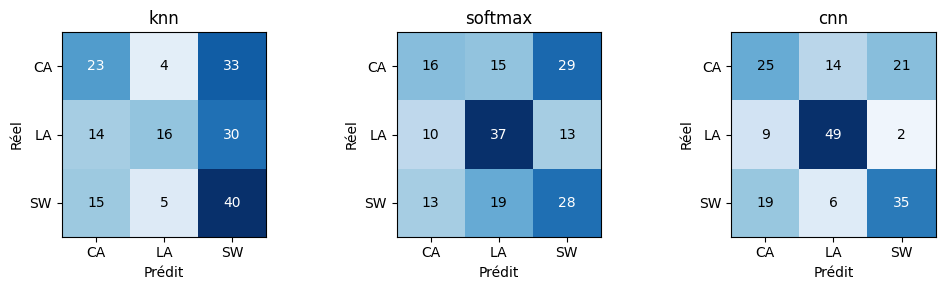

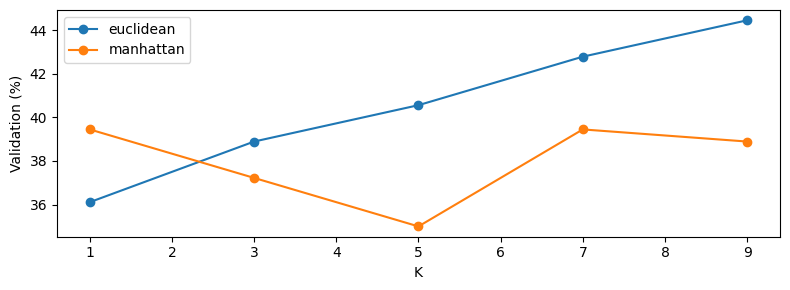

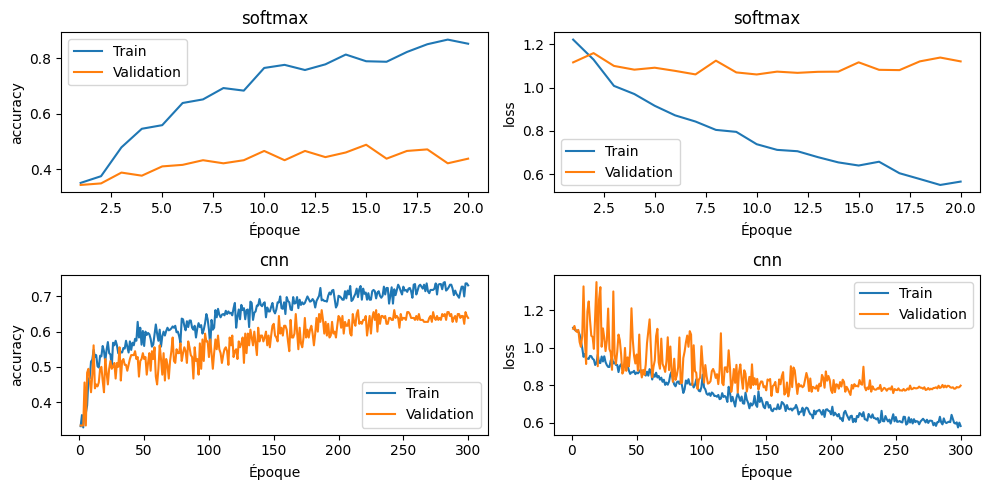

In [21]:
# Figures du premier pli, fixé avant les entraînements.
first = core_results[0]
matrices([(kind, first[kind]["confusion"]) for kind in ["knn", "softmax", "cnn"]])
plt.figure(figsize=(8, 3))
for distance in ["euclidean", "manhattan"]:
    grid = [r for r in first["knn"]["grid"] if r["metric"] == distance]
    plt.plot([r["k"] for r in grid], [100 * r["validation"] for r in grid], "o-", label=distance)
plt.xlabel("K"); plt.ylabel("Validation (%)"); plt.legend(); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(2, 2, figsize=(10, 5))
for row, kind in enumerate(["softmax", "cnn"]):
    history = HISTORIES[first[kind]["id"]]
    for col, metric in enumerate(["accuracy", "loss"]):
        axes[row, col].plot(np.arange(1, len(history[metric]) + 1), history[metric], label="Train")
        axes[row, col].plot(np.arange(1, len(history[metric]) + 1), history["val_" + metric], label="Validation")
        axes[row, col].set(title=kind, xlabel="Époque", ylabel=metric); axes[row, col].legend()
plt.tight_layout(); plt.show()

## 1.2. Ancien split et ablation de l'augmentation
Les anciennes premières 300 images/classe forment le split historique, distinct du nouveau tirage aléatoire.
L'ablation entraîne deux CNN avec les mêmes poids initiaux, lots et 300 époques ; seule l'augmentation change. Un Softmax est également entraîné pour les comparaisons appariées.

In [22]:
old_knn = entrainer_knn_pixels("historical900_knn", "1_historical", x_hist, y, small_split)
old_soft, _ = entrainer_pixels("historical900_softmax", "1_historical", x_hist, y, small_split,
                                "softmax", explicite=False, tableaux_numpy=True)
old_cnn, _ = entrainer_pixels("historical900_cnn", "1_historical", x_hist, y, small_split,
                               "cnn", seed=2, explicite=False, tableaux_numpy=True)
resume([old_knn, old_soft, old_cnn]);

ablation = {}
for kind, aug in [("cnn_noaug", False), ("cnn_aug", True), ("softmax", False)]:
    result, pred = entrainer_pixels("ablation_" + kind, "1_ablation", x_hist, y, small_split,
        "softmax" if kind == "softmax" else "cnn", augmentation=aug, aug_seed=11, pool=2)
    ablation[kind] = (result, pred)
assert ablation["cnn_noaug"][0]["initial_weights_hash"] == ablation["cnn_aug"][0]["initial_weights_hash"]
resume([ablation[k][0] for k in ["cnn_noaug", "cnn_aug", "softmax"]]);

historical900_softmax — époque 1/100 — val_accuracy=0.3444
historical900_cnn — époque 1/300 — val_accuracy=0.4111
historical900_cnn — époque 25/300 — val_accuracy=0.5167
historical900_cnn — époque 50/300 — val_accuracy=0.5333
historical900_cnn — époque 75/300 — val_accuracy=0.5667
historical900_cnn — époque 100/300 — val_accuracy=0.6111
historical900_cnn — époque 125/300 — val_accuracy=0.6056
historical900_cnn — époque 150/300 — val_accuracy=0.6000
historical900_cnn — époque 175/300 — val_accuracy=0.5833
historical900_cnn — époque 200/300 — val_accuracy=0.5500
historical900_cnn — époque 225/300 — val_accuracy=0.6222
historical900_cnn — époque 250/300 — val_accuracy=0.6056
historical900_cnn — époque 275/300 — val_accuracy=0.6222
historical900_cnn — époque 300/300 — val_accuracy=0.6278


| Modèle                | Validation (%)   | Test (%)   | P macro (%)   | R macro (%)   | F1 macro (%)   |
|:----------------------|:-----------------|:-----------|:--------------|:--------------|:---------------|
| historical900_knn     | 41.67            | 41.67      | 42.85         | 41.67         | 41.73          |
| historical900_softmax | 45.56            | 56.11      | 53.74         | 56.11         | 52.21          |
| historical900_cnn     | 62.78            | 61.11      | 61.49         | 61.11         | 60.89          |

ablation_cnn_noaug — époque 1/300 — val_accuracy=0.4167
ablation_cnn_noaug — époque 25/300 — val_accuracy=0.4722
ablation_cnn_noaug — époque 50/300 — val_accuracy=0.4667
ablation_cnn_noaug — époque 75/300 — val_accuracy=0.4778
ablation_cnn_noaug — époque 100/300 — val_accuracy=0.4833
ablation_cnn_noaug — époque 125/300 — val_accuracy=0.4778
ablation_cnn_noaug — époque 150/300 — val_accuracy=0.4889
ablation_cnn_noaug — époque 175/300 — val_accuracy=0.4778
ablation_cnn_noaug — époque 200/300 — val_accuracy=0.4778
ablation_cnn_noaug — époque 225/300 — val_accuracy=0.4778
ablation_cnn_noaug — époque 250/300 — val_accuracy=0.4778
ablation_cnn_noaug — époque 275/300 — val_accuracy=0.4722
ablation_cnn_noaug — époque 300/300 — val_accuracy=0.4722
ablation_cnn_aug — époque 1/300 — val_accuracy=0.3333
ablation_cnn_aug — époque 25/300 — val_accuracy=0.4556
ablation_cnn_aug — époque 50/300 — val_accuracy=0.5333
ablation_cnn_aug — époque 75/300 — val_accuracy=0.5833
ablation_cnn_aug — époque 100/30

| Modèle             | Validation (%)   | Test (%)   | P macro (%)   | R macro (%)   | F1 macro (%)   |
|:-------------------|:-----------------|:-----------|:--------------|:--------------|:---------------|
| ablation_cnn_noaug | 43.89            | 51.11      | 51.68         | 51.11         | 43.12          |
| ablation_cnn_aug   | 70.56            | 61.11      | 61.42         | 61.11         | 61.22          |
| ablation_softmax   | 39.44            | 53.33      | 53.03         | 53.33         | 49.61          |

In [23]:
paired = []
truth = y[small_split["test"]]
for a, b in [("cnn_aug", "cnn_noaug"), ("cnn_aug", "softmax"), ("cnn_noaug", "softmax")]:
    ca, cb = ablation[a][1] == truth, ablation[b][1] == truth
    na, nb = int((ca & ~cb).sum()), int((cb & ~ca).sum())
    p = binomtest(na, na + nb, .5).pvalue if na + nb else 1.
    paired.append({"Comparaison": a + " / " + b, "A seul correct": na, "B seul correct": nb, "p exact": p})
order = np.argsort([r["p exact"] for r in paired]); previous = 0.
for rank, i in enumerate(order):
    previous = max(previous, min(1., (len(order) - rank) * paired[i]["p exact"]))
    paired[i]["p Holm"] = previous
tableau(paired, 3); ecrire_json(RESULTS / "mcnemar.json", paired)

| Comparaison         | A seul correct   | B seul correct   | p exact   | p Holm   |
|:--------------------|:-----------------|:-----------------|:----------|:---------|
| cnn_aug / cnn_noaug | 52               | 34               | 0.066     | 0.198    |
| cnn_aug / softmax   | 46               | 32               | 0.141     | 0.281    |
| cnn_noaug / softmax | 40               | 44               | 0.744     | 0.744    |

# 2. Expérimentations complémentaires - 3000 images et application
## 2.1. Pixels et CNN sur 3000 images
Même groupe 1000 images/classe et split 1800/600/600. Pour le CNN étendu, la TTA (8 rotations/retournements) est retenue seulement si elle améliore la validation.

In [24]:
pixels3000_knn = entrainer_knn_pixels("pixels3000_knn", "2_baselines", x_hist, y, hist_split)
pixels3000_soft, _ = entrainer_pixels("pixels3000_softmax", "2_baselines", x_hist, y, hist_split,
                                      "softmax", explicite=False, tableaux_numpy=True)
cnn3000, _ = entrainer_pixels("cnn3000", "2_baselines", x_hist, y, hist_split,
                              "cnn", seed=2, explicite=False, tableaux_numpy=True)
cnn = tf.keras.models.load_model(MODELS / "cnn3000/model.keras", compile=False)

def proba_tta(model, x):
    views = []
    for k in range(4):
        rotated = np.rot90(x, k, axes=(1, 2)).copy()
        views.append(probabilites(model, rotated))
        views.append(probabilites(model, rotated[:, :, ::-1].copy()))
    return np.mean(views, axis=0)

va, te = hist_split["val"], hist_split["test"]
vp_tta = proba_tta(cnn, x_hist[va]).argmax(1)
use_tta = accuracy_score(y[va], vp_tta) > cnn3000["validation"]
REGISTRY["cnn3000"]["tta"] = bool(use_tta)
ecrire_json(MODELS / "cnn3000/metadata.json", REGISTRY["cnn3000"])
if use_tta:
    tp_tta = proba_tta(cnn, x_hist[te]).argmax(1)
    # Remplacer cette évaluation par celle de la règle retenue sur validation.
    RECORDS.remove(cnn3000)
    cnn3000 = enregistrer("cnn3000", "2_baselines", y[va], vp_tta, y[te], tp_tta,
                           HISTORIES["cnn3000"], tta=True)
print("TTA retenue :", use_tta)
resume([pixels3000_knn, pixels3000_soft, cnn3000]);
del cnn; tf.keras.backend.clear_session(); gc.collect()

pixels3000_softmax — époque 1/100 — val_accuracy=0.4350
cnn3000 — époque 1/300 — val_accuracy=0.3733
cnn3000 — époque 25/300 — val_accuracy=0.5667
cnn3000 — époque 50/300 — val_accuracy=0.5750
cnn3000 — époque 75/300 — val_accuracy=0.6217
cnn3000 — époque 100/300 — val_accuracy=0.6267
cnn3000 — époque 125/300 — val_accuracy=0.6567
cnn3000 — époque 150/300 — val_accuracy=0.6517
cnn3000 — époque 175/300 — val_accuracy=0.6600
cnn3000 — époque 200/300 — val_accuracy=0.6433
cnn3000 — époque 225/300 — val_accuracy=0.6550
cnn3000 — époque 250/300 — val_accuracy=0.6633
cnn3000 — époque 275/300 — val_accuracy=0.6717
cnn3000 — époque 300/300 — val_accuracy=0.6783
TTA retenue : True


| Modèle             | Validation (%)   | Test (%)   | P macro (%)   | R macro (%)   | F1 macro (%)   |
|:-------------------|:-----------------|:-----------|:--------------|:--------------|:---------------|
| pixels3000_knn     | 46.33            | 39.67      | 45.69         | 39.67         | 38.14          |
| pixels3000_softmax | 46.17            | 45.00      | 49.34         | 45.00         | 41.33          |
| cnn3000            | 70.17            | 69.00      | 68.60         | 69.00         | 68.68          |

0

## 2.2. EfficientNetB0, ResNet50 et InceptionV3
Les extracteurs ImageNet gelés sont appliqués aux images originales redimensionnées à 224 ou 299 pixels.
Les têtes sont entraînées ici : k-NN, Softmax linéaire, ou Dense64 + Dropout(0,3) + Dense3.
Chaque extracteur est sauvegardé une fois dans `shared/` ; ses classifieurs le référencent dans leurs métadonnées.

In [25]:
from tensorflow.keras.applications import EfficientNetB0, ResNet50, InceptionV3
from tensorflow.keras.applications.resnet50 import preprocess_input as preprocess_resnet
from tensorflow.keras.applications.inception_v3 import preprocess_input as preprocess_inception

BACKBONES = {"efficientnetb0": (EfficientNetB0, 224), "resnet50": (ResNet50, 224),
             "inceptionv3": (InceptionV3, 299)}
FEATURES = {}
for name, (constructor, size) in BACKBONES.items():
    tf.keras.backend.clear_session()
    base = constructor(weights="imagenet", include_top=False, pooling="avg", input_shape=(size, size, 3))
    base.trainable = False
    features = []
    for start in range(0, len(images), 32):
        x = tf.image.resize(images[start:start + 32], (size, size))
        if name == "resnet50": x = preprocess_resnet(x)
        if name == "inceptionv3": x = preprocess_inception(x)
        features.append(base(x, training=False).numpy())
    FEATURES[name] = np.concatenate(features)
    base.save(SHARED / f"{name}.keras")
    print(name, FEATURES[name].shape)
    del base; tf.keras.backend.clear_session(); gc.collect()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
efficientnetb0 (3000, 1280)
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
resnet50 (3000, 2048)
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
inceptionv3 (3000, 2048)


### Têtes de classification sur les caractéristiques
Une couche Dense(3) pour Softmax ; Dense64 → Dropout(0,3) → Dense3 pour les têtes ResNet50 et InceptionV3.

In [26]:
def tete_features(size, kind, seed, explicite):
    kwargs = {"kernel_initializer": tf.keras.initializers.GlorotUniform(seed=seed)} if explicite else {}
    layers = [tf.keras.layers.Input((size,))]
    if kind == "dense64":
        layers += [tf.keras.layers.Dense(64, activation="relu", **kwargs), tf.keras.layers.Dropout(.3)]
    layers += [tf.keras.layers.Dense(3, activation="softmax", **kwargs)]
    model = tf.keras.Sequential(layers)
    return model

In [27]:
def entrainer_features(model_id, section, xt, yt, xv, yv, xe, ye, extractor, kind="softmax",
                        seed=42, l2=False, explicite=True, tableaux_numpy=False, scaler_actif=True):
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    if l2:
        xt, xv, xe = [normalize(a, norm="l2") for a in [xt, xv, xe]]
    meta = {"family": "features", "extractor": extractor, "l2": l2,
            "input_size": 299 if extractor == "inceptionv3" else 224}
    if kind == "knn":
        best, grid = choisir_knn(xt, yt, xv, yv, [1, 3, 5, 7, 9, 11, 15, 21], poids="distance",
                distances=["euclidean"] if extractor == "efficientnetb0" else None)
        model = best[3]
        sauvegarder_knn(model_id, model, **meta)
        return enregistrer(model_id, section, yv, model.predict(xv), ye, model.predict(xe),
                            k=best[1], metric=best[2], grid=grid)
    scaler = None
    if scaler_actif:
        scaler = StandardScaler()
        xt, xv, xe = scaler.fit_transform(xt), scaler.transform(xv), scaler.transform(xe)
    model = tete_features(xt.shape[1], kind, seed, explicite)
    initial_hash = hashlib.sha256(model.get_weights()[0].tobytes()).hexdigest()
    epochs, patience = (EPOCHS_TETE, 5) if kind == "dense64" else (EPOCHS_SOFTMAX, 10)
    history = apprentissage(model, xt, yt, xv, yv, model_id, epochs, 1e-3, patience,
                             seed, tableaux_numpy)
    vp, tp = probabilites(model, xv).argmax(1), probabilites(model, xe).argmax(1)
    sauvegarder_tf(model_id, model, **meta, scaler="scaler.joblib" if scaler is not None else None)
    if scaler is not None:
        joblib.dump(scaler, MODELS / model_id / "scaler.joblib")
    if kind != "dense64":
        W, b = model.layers[-1].get_weights()
        np.savez_compressed(MODELS / model_id / "head_weights.npz", W=W, b=b)
    result = enregistrer(model_id, section, yv, vp, ye, tp, history,
                          initial_weights_hash=initial_hash, seed=seed)
    del model; tf.keras.backend.clear_session(); gc.collect()
    return result

In [28]:
tr, va, te = [hist_split[k] for k in ["train", "val", "test"]]
feature_baselines = []
for extractor, kind in [("efficientnetb0", "knn"), ("efficientnetb0", "softmax"),
                         ("resnet50", "dense64"), ("inceptionv3", "dense64")]:
    f = FEATURES[extractor]
    result = entrainer_features(extractor + "_" + kind, "2_baselines", f[tr], y[tr], f[va], y[va],
                                f[te], y[te], extractor, kind, explicite=False,
                                tableaux_numpy=True, scaler_actif=kind != "dense64")
    feature_baselines.append(result)
resume(feature_baselines);

efficientnetb0_softmax — époque 1/100 — val_accuracy=0.7783
resnet50_dense64 — époque 1/40 — val_accuracy=0.8017
inceptionv3_dense64 — époque 1/40 — val_accuracy=0.6850
inceptionv3_dense64 — époque 25/40 — val_accuracy=0.8317


| Modèle                 | Validation (%)   | Test (%)   | P macro (%)   | R macro (%)   | F1 macro (%)   |
|:-----------------------|:-----------------|:-----------|:--------------|:--------------|:---------------|
| efficientnetb0_knn     | 84.00            | 80.17      | 80.30         | 80.17         | 79.85          |
| efficientnetb0_softmax | 85.00            | 85.00      | 84.98         | 85.00         | 84.94          |
| resnet50_dense64       | 88.50            | 86.00      | 86.28         | 86.00         | 86.03          |
| inceptionv3_dense64    | 84.00            | 80.00      | 79.87         | 80.00         | 79.74          |

## 2.3. ResNet50 fine-tuné
Première phase : backbone gelé, Adam 0,001, au plus 40 époques.
Seconde phase : seules les couches `conv5_` hors BatchNorm sont dégelées, Adam 0,00001, au plus 20 époques.
Les BatchNorm restent en inférence. Le prétraitement sérialisable évite une couche Lambda difficile à recharger.

In [29]:
@tf.keras.utils.register_keras_serializable(package="DeepWeeds")
class ResNetPreprocess(tf.keras.layers.Layer):
    def call(self, inputs):
        return tf.keras.applications.resnet50.preprocess_input(inputs)

# La même définition sera écrite dans le module d'inférence de l'export.
tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(42)
base_ft = ResNet50(weights="imagenet", include_top=False, pooling="avg", input_shape=(224, 224, 3))
base_ft.trainable = False
inputs = tf.keras.layers.Input((224, 224, 3))
x = tf.keras.layers.RandomFlip("horizontal_and_vertical")(inputs)
x = tf.keras.layers.RandomRotation(.1)(x)
x = ResNetPreprocess()(x)
x = base_ft(x, training=False)
x = tf.keras.layers.Dense(64, activation="relu")(x)
x = tf.keras.layers.Dropout(.3)(x)
outputs = tf.keras.layers.Dense(3, activation="softmax")(x)
resnet_ft = tf.keras.Model(inputs, outputs)

In [30]:
def images_ds(indices, training=False):
    ds = dataset(images[indices], y[indices], seed=42, melanger=training, batch=16)
    return ds.map(lambda a, b: (tf.image.resize(a, (224, 224)), b), num_parallel_calls=1)

train_ft_ds, val_ft_ds, test_ft_ds = images_ds(tr, True), images_ds(va), images_ds(te)

def phase_resnet(model, phase, epochs, lr, train_ds, val_ds):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    path = dossier_modele("resnet50_finetuned") / (phase + ".weights.h5")
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, shuffle=False, verbose=0,
                  callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
                             tf.keras.callbacks.ModelCheckpoint(path, monitor="val_loss", save_best_only=True, save_weights_only=True), Progression("resnet50_" + phase, epochs)])
    model.load_weights(path); path.unlink()
    return h.history

In [31]:
head_history = phase_resnet(resnet_ft, "head", EPOCHS_TETE, 1e-3, train_ft_ds, val_ft_ds)
base_ft.trainable = True
for layer in base_ft.layers:
    layer.trainable = layer.name.startswith("conv5_") and not isinstance(layer, tf.keras.layers.BatchNormalization)
assert all(not layer.trainable for layer in base_ft.layers if isinstance(layer, tf.keras.layers.BatchNormalization))
fine_history = phase_resnet(resnet_ft, "fine", EPOCHS_FINETUNING, 1e-5, train_ft_ds, val_ft_ds)
vp = resnet_ft.predict(val_ft_ds, verbose=0).argmax(1)
tp = resnet_ft.predict(test_ft_ds, verbose=0).argmax(1)
sauvegarder_tf("resnet50_finetuned", resnet_ft, family="resnet_finetuned", input_size=224,
               scaling="raw_0_255_preprocessing_inside_model")
resnet_result = enregistrer("resnet50_finetuned", "2_baselines", y[va], vp, y[te], tp, fine_history)
ecrire_json(MODELS / "resnet50_finetuned/head_history.json", head_history)
resume([resnet_result]);
del resnet_ft, base_ft, train_ft_ds, val_ft_ds, test_ft_ds; tf.keras.backend.clear_session(); gc.collect()

resnet50_head — époque 1/40 — val_accuracy=0.7283
resnet50_fine — époque 1/20 — val_accuracy=0.8767


| Modèle             | Validation (%)   | Test (%)   | P macro (%)   | R macro (%)   | F1 macro (%)   |
|:-------------------|:-----------------|:-----------|:--------------|:--------------|:---------------|
| resnet50_finetuned | 92.00            | 89.33      | 89.70         | 89.33         | 89.21          |

0

## 2.4. DINOv2 : extraction des caractéristiques
DINOv2 ViT-S/14 est gelé. Chaque image est transformée en un vecteur de 384 caractéristiques.<br>
Deux vues augmentées supplémentaires sont produites uniquement pour les images d'entraînement : retournements horizontal/vertical, rotation ±15°, luminosité et contraste 0,1.

In [32]:
DINO_COMMIT = "7764ea0f912e53c92e82eb78a2a1631e92725fc8"
source_zip = telecharger(f"https://codeload.github.com/facebookresearch/dinov2/zip/{DINO_COMMIT}", RAW / "dinov2_source.zip")
source_root = RAW / ("dinov2-" + DINO_COMMIT)
if not source_root.exists():
    with zipfile.ZipFile(source_zip) as archive:
        archive.extractall(RAW)
DINO_WEIGHTS = telecharger(
    "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth",
    RAW / "dinov2_vits14_pretrain.pth",
    sha256="b938bf1bc15cd2ec0feacfe3a1bb553fe8ea9ca46a7e1d8d00217f29aef60cd9")
shutil.copy2(DINO_WEIGHTS, SHARED / DINO_WEIGHTS.name)
sys.path.insert(0, str(source_root))
from dinov2.hub.backbones import dinov2_vits14
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dino = dinov2_vits14(pretrained=False)
dino.load_state_dict(torch.load(DINO_WEIGHTS, map_location="cpu", weights_only=True))
dino = dino.to(DEVICE).eval()

Téléchargé : dinov2_source.zip
Téléchargé : dinov2_vits14_pretrain.pth


/content/deepweeds_execution/images/dinov2-7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/swiglu_ffn.py:45: UserWarning: xFormers is disabled (SwiGLU)
  warnings.warn("xFormers is disabled (SwiGLU)")
/content/deepweeds_execution/images/dinov2-7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/content/deepweeds_execution/images/dinov2-7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/attention.py:29: UserWarning: xFormers is disabled (Attention)
  warnings.warn("xFormers is disabled (Attention)")
/content/deepweeds_execution/images/dinov2-7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/content/deepweeds_execution/images/dinov2-7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/block.py:35: UserWarning: xFormers is di

In [33]:
normal_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
    transforms.Normalize([.485, .456, .406], [.229, .224, .225])])
augment_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(), transforms.RandomRotation(15), transforms.ColorJitter(brightness=.1, contrast=.1),
    transforms.ToTensor(), transforms.Normalize([.485, .456, .406], [.229, .224, .225])])

def extraire_dino(array, transform=normal_transform):
    features = []
    with torch.inference_mode():
        for start in range(0, len(array), 16):
            batch = torch.stack([transform(Image.fromarray(im)) for im in array[start:start + 16]]).to(DEVICE)
            features.append(dino(batch).cpu().numpy())
    return np.concatenate(features)

In [34]:
features_dino = extraire_dino(images)
torch.manual_seed(42); np.random.seed(42)
import random
random.seed(42)
features_aug = np.concatenate([extraire_dino(images[tr], augment_transform) for _ in range(2)])
y_aug = np.tile(y[tr], 2)
assert features_dino.shape == (len(y), 384)
assert len(features_aug) == 2 * len(tr)
print("Features originales :", features_dino.shape, "— vues supplémentaires train :", features_aug.shape)
# Les tableaux générés sont sauvegardés pour la traçabilité, sans être relus comme entrées.
np.savez_compressed(RESULTS / "features_dino_generated.npz", features=features_dino, y=y, image_hash=image_hash)
shutil.copytree(source_root / "dinov2", SHARED / "dinov2_source/dinov2", dirs_exist_ok=True, ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
shutil.copy2(source_root / "LICENSE", SHARED / "dinov2_source/LICENSE")
ecrire_json(SHARED / "dinov2_source/version.json", {"commit": DINO_COMMIT})

Features originales : (3000, 384) — vues supplémentaires train : (3600, 384)


In [35]:
# Série 1 : même groupe historique, extracteur gelé, têtes réentraînées.
dino_baselines = []
for kind in ["knn", "softmax"]:
    result = entrainer_features("dino_series1_" + kind, "2_baselines", features_dino[tr], y[tr],
        features_dino[va], y[va], features_dino[te], y[te], "dinov2", kind,
        explicite=False, tableaux_numpy=True)
    dino_baselines.append(result)

dino_series1_softmax — époque 1/100 — val_accuracy=0.8617
dino_series1_softmax — époque 25/100 — val_accuracy=0.9317


### Normalisation L2 et augmentation
Deux vues supplémentaires par image train. Les scalers sont ajustés uniquement sur les données d'entraînement.

In [36]:
# Série 2 : 4 variantes ; initialiseur explicite pour la tête Softmax.
variants = [("baseline", False, False), ("l2", True, False),
            ("augmentation", False, True), ("l2_augmentation", True, True)]
variant_results = []
for name, l2, aug in variants:
    xt = np.concatenate([features_dino[tr], features_aug]) if aug else features_dino[tr]
    yt = np.concatenate([y[tr], y_aug]) if aug else y[tr]
    for kind in ["knn", "softmax"]:
        result = entrainer_features("dino_" + kind + "_" + name, "2_variants", xt, yt,
            features_dino[va], y[va], features_dino[te], y[te], "dinov2", kind,
            l2=l2, tableaux_numpy=True)
        result["variant"] = name
        variant_results.append(result)
resume(dino_baselines);
# Choix uniquement sur validation ; le test ne choisit pas une variante.
recommended = {}
for kind in ["knn", "softmax"]:
    candidates = [r for r in variant_results if r["id"].startswith("dino_" + kind + "_")]
    recommended["dino_" + kind] = max(candidates, key=lambda r: r["validation"])["id"]
recommended["resnet50_finetuned"] = "resnet50_finetuned"
tableau([{"Variante": r["id"], "Validation (%)": 100 * r["validation"],
          "Test (%)": 100 * r["accuracy"], "F1 macro (%)": 100 * r["f1_macro"]} for r in variant_results]);
print("Modèles retenus sur validation :", recommended)

dino_softmax_baseline — époque 1/100 — val_accuracy=0.8300
dino_softmax_baseline — époque 25/100 — val_accuracy=0.9467
dino_softmax_l2 — époque 1/100 — val_accuracy=0.8333
dino_softmax_l2 — époque 25/100 — val_accuracy=0.9467
dino_softmax_augmentation — époque 1/100 — val_accuracy=0.8800
dino_softmax_l2_augmentation — époque 1/100 — val_accuracy=0.8867


| Modèle               | Validation (%)   | Test (%)   | P macro (%)   | R macro (%)   | F1 macro (%)   |
|:---------------------|:-----------------|:-----------|:--------------|:--------------|:---------------|
| dino_series1_knn     | 93.00            | 91.33      | 91.48         | 91.33         | 91.34          |
| dino_series1_softmax | 93.33            | 91.50      | 91.59         | 91.50         | 91.51          |

| Variante                     | Validation (%)   | Test (%)   | F1 macro (%)   |
|:-----------------------------|:-----------------|:-----------|:---------------|
| dino_knn_baseline            | 93.00            | 91.33      | 91.34          |
| dino_softmax_baseline        | 94.67            | 92.50      | 92.51          |
| dino_knn_l2                  | 94.00            | 90.67      | 90.69          |
| dino_softmax_l2              | 94.67            | 92.50      | 92.51          |
| dino_knn_augmentation        | 93.00            | 92.33      | 92.31          |
| dino_softmax_augmentation    | 93.33            | 93.67      | 93.68          |
| dino_knn_l2_augmentation     | 93.67            | 90.67      | 90.67          |
| dino_softmax_l2_augmentation | 93.33            | 93.83      | 93.85          |

Modèles retenus sur validation : {'dino_knn': 'dino_knn_l2', 'dino_softmax': 'dino_softmax_baseline', 'resnet50_finetuned': 'resnet50_finetuned'}


## 2.5. Contrôle de l'initialisation - cinq seeds
Mêmes features, mêmes indices, même StandardScaler et même ordre des lots pour une seed donnée.
On compare Dense par défaut après seed globale et `GlorotUniform(seed=seed)` explicite, sans augmentation.

In [37]:
initializer_results = []
for seed in SEEDS:
    for method in ["implicit", "explicit"]:
        result = entrainer_features(f"initializer_{method}_{seed}", "2_initializers",
            features_dino[tr], y[tr], features_dino[va], y[va], features_dino[te], y[te],
            "dinov2", "softmax", seed=seed, explicite=method == "explicit")
        result.update(initializer=method)
        initializer_results.append(result)
tableau([{"Initialisation": method,
          "Test moyen (%)": 100 * np.mean([r["accuracy"] for r in initializer_results if r["initializer"] == method]),
          "Écart-type (points)": 100 * np.std([r["accuracy"] for r in initializer_results if r["initializer"] == method],
                                             ddof=1) if len(SEEDS) > 1 else 0.}
         for method in ["implicit", "explicit"]]);

initializer_implicit_40 — époque 1/100 — val_accuracy=0.8750
initializer_implicit_40 — époque 25/100 — val_accuracy=0.9333
initializer_explicit_40 — époque 1/100 — val_accuracy=0.8417
initializer_explicit_40 — époque 25/100 — val_accuracy=0.9333
initializer_implicit_41 — époque 1/100 — val_accuracy=0.8700
initializer_implicit_41 — époque 25/100 — val_accuracy=0.9417
initializer_explicit_41 — époque 1/100 — val_accuracy=0.8483
initializer_explicit_41 — époque 25/100 — val_accuracy=0.9417
initializer_implicit_42 — époque 1/100 — val_accuracy=0.8667
initializer_implicit_42 — époque 25/100 — val_accuracy=0.9300
initializer_explicit_42 — époque 1/100 — val_accuracy=0.8400
initializer_explicit_42 — époque 25/100 — val_accuracy=0.9450
initializer_implicit_43 — époque 1/100 — val_accuracy=0.8783
initializer_implicit_43 — époque 25/100 — val_accuracy=0.9467
initializer_explicit_43 — époque 1/100 — val_accuracy=0.8600
initializer_explicit_43 — époque 25/100 — val_accuracy=0.9300
initializer_impl

| Initialisation   | Test moyen (%)   | Écart-type (points)   |
|:-----------------|:-----------------|:----------------------|
| implicit         | 91.97            | 0.66                  |
| explicit         | 92.07            | 0.49                  |

## 2.6. DINOv2 - cinq plis aléatoires et cinq plis par dates
Le groupe est la date des huit premiers caractères du nom JPEG, **tous appareils confondus**.
Aucune date ne peut être partagée entre train, validation et test dans le protocole groupé. Les scalers et têtes sont réappris à chaque pli ; le test reste exclu des réglages.
OOF concatène une seule prédiction test par image. Les dates sont un proxy de session, pas des sites GPS.

In [38]:
groups = np.array([name[:8] for name in names])
date_splits = []
for protocol in ["random", "date_grouped"]:
    outer = (StratifiedKFold(PLIS, shuffle=True, random_state=42) if protocol == "random"
             else StratifiedGroupKFold(PLIS, shuffle=True, random_state=42))
    iterator = outer.split(features_dino, y) if protocol == "random" else outer.split(features_dino, y, groups)
    for fold, (tv, test) in enumerate(iterator):
        if protocol == "random":
            train, val = train_test_split(tv, test_size=.25, random_state=42 + fold, stratify=y[tv])
        else:
            inner = StratifiedGroupKFold(4, shuffle=True, random_state=42 + fold)
            for a, b in inner.split(features_dino[tv], y[tv], groups[tv]):
                train, val = tv[a], tv[b]
                if len(np.unique(y[train])) == len(np.unique(y[val])) == 3:
                    break
            else:
                raise ValueError("La validation doit contenir les trois classes.")
            assert not (set(groups[train]) & set(groups[val]) or set(groups[train]) & set(groups[test])
                        or set(groups[val]) & set(groups[test]))
        date_splits.append({"protocol": protocol, "fold": fold,
            "train": train.tolist(), "val": val.tolist(), "test": test.tolist(),
            "train_dates": sorted(set(groups[train])), "val_dates": sorted(set(groups[val])),
            "test_dates": sorted(set(groups[test]))})

In [39]:
dino_cv = []
OOF = {(p, k): np.full(len(y), -1) for p in ["random", "date_grouped"] for k in ["softmax", "knn"]}
for split in date_splits:
    protocol, fold = split["protocol"], split["fold"]
    train, val, test = [np.asarray(split[k]) for k in ["train", "val", "test"]]
    for kind in ["softmax", "knn"]:
        model_id = f"dino_{protocol}_fold{fold:02d}_{kind}"
        result = entrainer_features(model_id, "2_cv", features_dino[train], y[train],
            features_dino[val], y[val], features_dino[test], y[test], "dinov2", kind, seed=42 + fold)
        pred = np.load(MODELS / model_id / "predictions.npz")["prediction"]
        assert np.all(OOF[protocol, kind][test] == -1)
        OOF[protocol, kind][test] = pred
        result.update(protocol=protocol, fold=fold, test_n=len(test))
        dino_cv.append(result)
for pred in OOF.values():
    assert np.all(pred >= 0)

dino_random_fold00_softmax — époque 1/100 — val_accuracy=0.8617
dino_random_fold00_softmax — époque 25/100 — val_accuracy=0.9333
dino_random_fold01_softmax — époque 1/100 — val_accuracy=0.8500
dino_random_fold01_softmax — époque 25/100 — val_accuracy=0.9367
dino_random_fold02_softmax — époque 1/100 — val_accuracy=0.8250
dino_random_fold02_softmax — époque 25/100 — val_accuracy=0.9217
dino_random_fold03_softmax — époque 1/100 — val_accuracy=0.8783
dino_random_fold03_softmax — époque 25/100 — val_accuracy=0.9200
dino_random_fold04_softmax — époque 1/100 — val_accuracy=0.8500
dino_random_fold04_softmax — époque 25/100 — val_accuracy=0.9383
dino_date_grouped_fold00_softmax — époque 1/100 — val_accuracy=0.7871
dino_date_grouped_fold01_softmax — époque 1/100 — val_accuracy=0.7695
dino_date_grouped_fold01_softmax — époque 25/100 — val_accuracy=0.8580
dino_date_grouped_fold02_softmax — époque 1/100 — val_accuracy=0.7852
dino_date_grouped_fold03_softmax — époque 1/100 — val_accuracy=0.7898
dino

| Protocole    | Tête    | Moyenne plis (%)   | Écart-type (points)   | Accuracy OOF (%)   | F1 OOF (%)   |
|:-------------|:--------|:-------------------|:----------------------|:-------------------|:-------------|
| random       | softmax | 92.47              | 1.28                  | 92.47              | 92.46        |
| random       | knn     | 91.47              | 1.35                  | 91.47              | 91.47        |
| date_grouped | softmax | 84.02              | 1.36                  | 83.97              | 84.01        |
| date_grouped | knn     | 80.93              | 4.08                  | 80.83              | 81.01        |

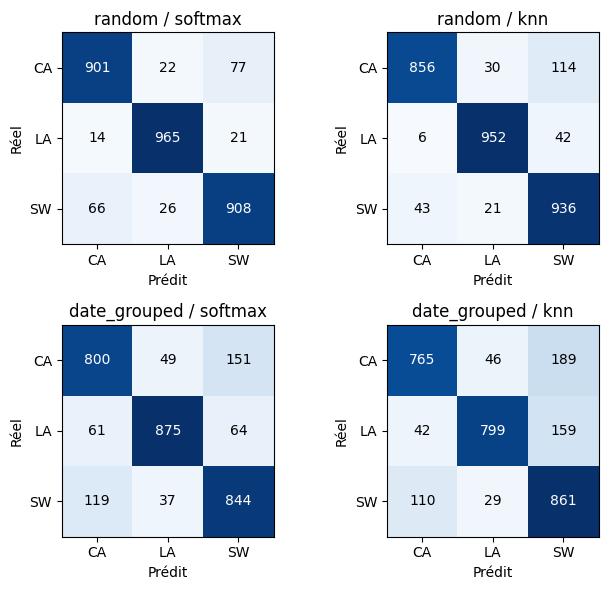

In [40]:
ecrire_json(RESULTS / "date_splits.json", date_splits)
oof_scores = {key: mesures(y, pred) for key, pred in OOF.items()}
rows = []
for protocol in ["random", "date_grouped"]:
    for kind in ["softmax", "knn"]:
        values = 100 * np.array([r["accuracy"] for r in dino_cv if r["protocol"] == protocol and r["id"].endswith(kind)])
        scores = oof_scores[protocol, kind]
        rows.append({"Protocole": protocol, "Tête": kind, "Moyenne plis (%)": values.mean(),
                     "Écart-type (points)": values.std(ddof=1), "Accuracy OOF (%)": 100 * scores["accuracy"],
                     "F1 OOF (%)": 100 * scores["f1_macro"]})
tableau(rows);
matrices([(protocol + " / " + kind, oof_scores[protocol, kind]["confusion"])
          for protocol in ["random", "date_grouped"] for kind in ["softmax", "knn"]], colonnes=2)

In [41]:
# Détail par classe des prédictions OOF, comme dans l'annexe du rapport.
oof_class_rows = []
for (protocol, kind), m in oof_scores.items():
    for i, label in enumerate(CLASSES):
        oof_class_rows.append({"Protocole": protocol, "Tête": kind, "Classe": label,
            "Précision (%)": 100 * m["precision"][i], "Rappel (%)": 100 * m["recall"][i],
            "F1 (%)": 100 * m["f1"][i]})
tableau(oof_class_rows);
ecrire_json(RESULTS / "oof_results.json", [{"protocol": p, "model": k, **m} for (p, k), m in oof_scores.items()])

| Protocole    | Tête    | Classe       | Précision (%)   | Rappel (%)   | F1 (%)   |
|:-------------|:--------|:-------------|:----------------|:-------------|:---------|
| random       | softmax | Chinee apple | 91.85           | 90.10        | 90.96    |
| random       | softmax | Lantana      | 95.26           | 96.50        | 95.88    |
| random       | softmax | Snake weed   | 90.26           | 90.80        | 90.53    |
| random       | knn     | Chinee apple | 94.59           | 85.60        | 89.87    |
| random       | knn     | Lantana      | 94.92           | 95.20        | 95.06    |
| random       | knn     | Snake weed   | 85.71           | 93.60        | 89.48    |
| date_grouped | softmax | Chinee apple | 81.63           | 80.00        | 80.81    |
| date_grouped | softmax | Lantana      | 91.05           | 87.50        | 89.24    |
| date_grouped | softmax | Snake weed   | 79.70           | 84.40        | 81.98    |
| date_grouped | knn     | Chinee apple | 83.42           | 76.50        | 79.81    |
| date_grouped | knn     | Lantana      | 91.42           | 79.90        | 85.27    |
| date_grouped | knn     | Snake weed   | 71.22           | 86.10        | 77.95    |

## 2.7. Résultats sur le groupe étendu
Accuracy, précision macro, rappel macro et F1 macro, suivis des matrices de confusion et des résultats par classe.

| Modèle                 | Validation (%)   | Test (%)   | P macro (%)   | R macro (%)   | F1 macro (%)   |
|:-----------------------|:-----------------|:-----------|:--------------|:--------------|:---------------|
| dino_series1_softmax   | 93.33            | 91.50      | 91.59         | 91.50         | 91.51          |
| dino_series1_knn       | 93.00            | 91.33      | 91.48         | 91.33         | 91.34          |
| resnet50_finetuned     | 92.00            | 89.33      | 89.70         | 89.33         | 89.21          |
| resnet50_dense64       | 88.50            | 86.00      | 86.28         | 86.00         | 86.03          |
| efficientnetb0_softmax | 85.00            | 85.00      | 84.98         | 85.00         | 84.94          |
| efficientnetb0_knn     | 84.00            | 80.17      | 80.30         | 80.17         | 79.85          |
| inceptionv3_dense64    | 84.00            | 80.00      | 79.87         | 80.00         | 79.74          |
| cnn3000                | 70.17            | 69.00      | 68.60         | 69.00         | 68.68          |
| pixels3000_knn         | 46.33            | 39.67      | 45.69         | 39.67         | 38.14          |
| pixels3000_softmax     | 46.17            | 45.00      | 49.34         | 45.00         | 41.33          |

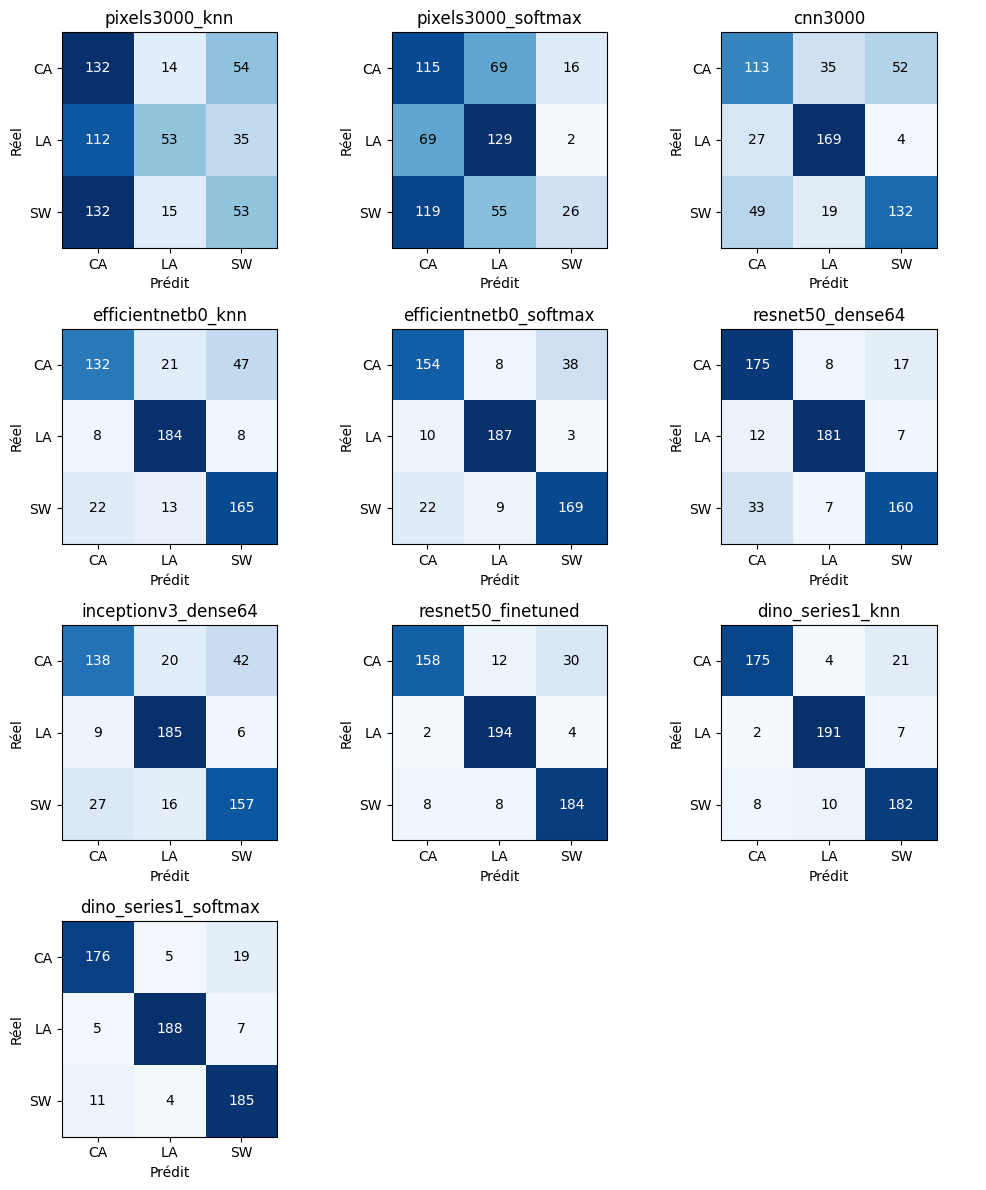

| Modèle                 | Classe       | Effectif   | Précision (%)   | Rappel (%)   | F1 (%)   |
|:-----------------------|:-------------|:-----------|:----------------|:-------------|:---------|
| pixels3000_knn         | Chinee apple | 200        | 35.11           | 66.00        | 45.83    |
| pixels3000_knn         | Lantana      | 200        | 64.63           | 26.50        | 37.59    |
| pixels3000_knn         | Snake weed   | 200        | 37.32           | 26.50        | 30.99    |
| pixels3000_softmax     | Chinee apple | 200        | 37.95           | 57.50        | 45.73    |
| pixels3000_softmax     | Lantana      | 200        | 50.99           | 64.50        | 56.95    |
| pixels3000_softmax     | Snake weed   | 200        | 59.09           | 13.00        | 21.31    |
| cnn3000                | Chinee apple | 200        | 59.79           | 56.50        | 58.10    |
| cnn3000                | Lantana      | 200        | 75.78           | 84.50        | 79.91    |
| cnn3000                | Snake weed   | 200        | 70.21           | 66.00        | 68.04    |
| efficientnetb0_knn     | Chinee apple | 200        | 81.48           | 66.00        | 72.93    |
| efficientnetb0_knn     | Lantana      | 200        | 84.40           | 92.00        | 88.04    |
| efficientnetb0_knn     | Snake weed   | 200        | 75.00           | 82.50        | 78.57    |
| efficientnetb0_softmax | Chinee apple | 200        | 82.80           | 77.00        | 79.79    |
| efficientnetb0_softmax | Lantana      | 200        | 91.67           | 93.50        | 92.57    |
| efficientnetb0_softmax | Snake weed   | 200        | 80.48           | 84.50        | 82.44    |
| resnet50_dense64       | Chinee apple | 200        | 79.55           | 87.50        | 83.33    |
| resnet50_dense64       | Lantana      | 200        | 92.35           | 90.50        | 91.41    |
| resnet50_dense64       | Snake weed   | 200        | 86.96           | 80.00        | 83.33    |
| inceptionv3_dense64    | Chinee apple | 200        | 79.31           | 69.00        | 73.80    |
| inceptionv3_dense64    | Lantana      | 200        | 83.71           | 92.50        | 87.89    |
| inceptionv3_dense64    | Snake weed   | 200        | 76.59           | 78.50        | 77.53    |
| resnet50_finetuned     | Chinee apple | 200        | 94.05           | 79.00        | 85.87    |
| resnet50_finetuned     | Lantana      | 200        | 90.65           | 97.00        | 93.72    |
| resnet50_finetuned     | Snake weed   | 200        | 84.40           | 92.00        | 88.04    |
| dino_series1_knn       | Chinee apple | 200        | 94.59           | 87.50        | 90.91    |
| dino_series1_knn       | Lantana      | 200        | 93.17           | 95.50        | 94.32    |
| dino_series1_knn       | Snake weed   | 200        | 86.67           | 91.00        | 88.78    |
| dino_series1_softmax   | Chinee apple | 200        | 91.67           | 88.00        | 89.80    |
| dino_series1_softmax   | Lantana      | 200        | 95.43           | 94.00        | 94.71    |
| dino_series1_softmax   | Snake weed   | 200        | 87.68           | 92.50        | 90.02    |

In [42]:
baseline_rows = [r for r in RECORDS if r["section"] == "2_baselines"]
resume(sorted(baseline_rows, key=lambda r: r["validation"], reverse=True));
matrices([(r["id"], r["confusion"]) for r in baseline_rows])
per_class = []
for r in baseline_rows:
    for i, label in enumerate(CLASSES):
        per_class.append({"Modèle": r["id"], "Classe": label, "Effectif": r["support"][i],
                          "Précision (%)": 100 * r["precision"][i], "Rappel (%)": 100 * r["recall"][i],
                          "F1 (%)": 100 * r["f1"][i]})
tableau(per_class);

## 2.8. Évaluation externe : 36 photographies
Les noms, étiquettes et URL du panel sont fixés dans `ressources/photos_externes.csv`, avant les prédictions.
Les photographies sont évaluées avec le nouveau modèle DINOv2 + Softmax baseline.

In [43]:
photos = pd.read_csv(RESSOURCES / "photos_externes.csv")
external_dir = ROOT / "photos_externes"
external_dir.mkdir(exist_ok=True)
external_images, external_y, external_manifest = [], [], []
for photo in photos.itertuples():
    path = telecharger(photo.url, external_dir / photo.filename)
    external_images.append(Image.open(path).convert("RGB"))
    external_y.append(photo.label)
    external_manifest.append({"url": photo.url, "label": photo.label,
                              "sha256": empreinte(path), "credits": photo.credits})
external_y = np.asarray(external_y)
ecrire_json(RESULTS / "external_manifest.json", external_manifest)

Téléchargé : ziziphusmauritiana8.jpg
Téléchargé : ziziphusmauritiana5.jpg
Téléchargé : ziziphusmauritiana11.jpg
Téléchargé : ziziphusmauritiana4.jpg
Téléchargé : ziziphusmauritiana2cg.jpg
Téléchargé : ziziphusmauritiana13.jpg
Téléchargé : ziziphusmauritiana7.jpg
Téléchargé : ziziphusmauritiana3.jpg
Téléchargé : ziziphusmauritiana10.jpg
Téléchargé : ziziphusmauritiana14lp.jpg
Téléchargé : ziziphusmauritiana2.jpg
Téléchargé : ziziphusmauritiana1cg.jpg
Téléchargé : lantanacamara1.jpg
Téléchargé : lantanacamara9.jpg
Téléchargé : lantanacamara11.jpg
Téléchargé : lantanacamara6.jpg
Téléchargé : lantanacamara22.jpg
Téléchargé : lantanacamara13.jpg
Téléchargé : lantanacamara20.jpg
Téléchargé : lantanacamara16.jpg
Téléchargé : lantanacamara17.jpg
Téléchargé : lantanacamara19.jpg
Téléchargé : lantanacamara4.jpg
Téléchargé : lantanacamara18.jpg
Téléchargé : stachytarphetajamaicensis13lp.jpg
Téléchargé : stachytarphetajamaicensis9.jpg
Téléchargé : stachytarphetajamaicensis6.jpg
Téléchargé : stachy

In [44]:
with torch.inference_mode():
    external_features = np.concatenate([dino(torch.stack([normal_transform(im) for im in external_images[start:start + 16]])
                          .to(DEVICE)).cpu().numpy() for start in range(0, len(external_images), 16)])
BASELINE_EXPORT = "dino_softmax_baseline"
external_head = tf.keras.models.load_model(MODELS / BASELINE_EXPORT / "model.keras", compile=False)
external_scaler = joblib.load(MODELS / BASELINE_EXPORT / "scaler.joblib")
external_proba = probabilites(external_head, external_scaler.transform(external_features))
external_scores = mesures(external_y, external_proba.argmax(1))

| Images   | Correctes   | Accuracy (%)   | F1 macro (%)   | IC Wilson 95 %   |
|:---------|:------------|:---------------|:---------------|:-----------------|
| 36       | 23          | 63.89          | 61.46          | [47.58 ; 77.52]  |

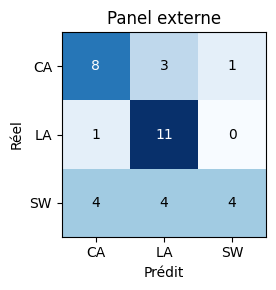

In [45]:
correct = int((external_y == external_proba.argmax(1)).sum())
z = norm.ppf(.975); total = len(external_y); p = correct / total; den = 1 + z*z/total
centre = (p + z*z/(2*total)) / den
half = z * np.sqrt(p*(1-p)/total + z*z/(4*total*total)) / den
tableau([{"Images": total, "Correctes": correct, "Accuracy (%)": 100 * external_scores["accuracy"],
          "F1 macro (%)": 100 * external_scores["f1_macro"],
          "IC Wilson 95 %": f"[{100*(centre-half):.2f} ; {100*(centre+half):.2f}]"}]);
matrices([("Panel externe", external_scores["confusion"])], colonnes=1)
ecrire_json(RESULTS / "external_manifest.json", external_manifest)
ecrire_json(RESULTS / "external_results.json", external_scores)
np.savez_compressed(RESULTS / "external_predictions.npz", y_true=external_y, probabilities=external_proba)

### Exemples de prédictions

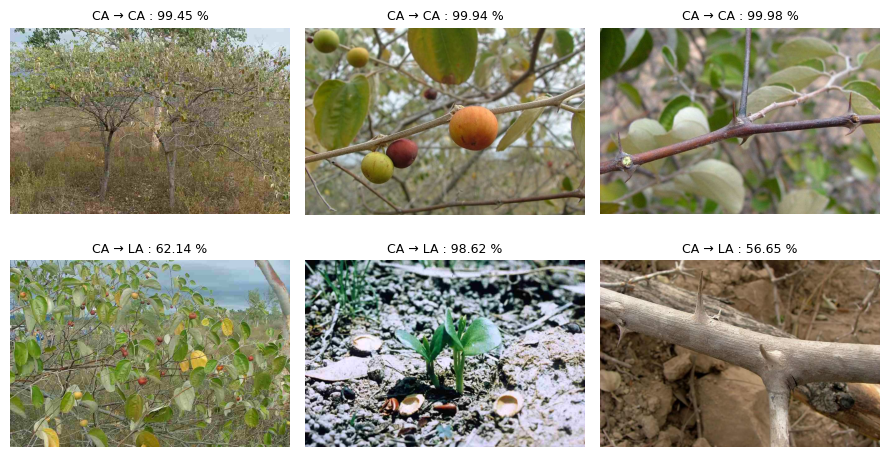

In [46]:
pred_ext = external_proba.argmax(1)
chosen = list(np.flatnonzero(pred_ext == external_y)[:3]) + list(np.flatnonzero(pred_ext != external_y)[:3])
fig, axes = plt.subplots(2, 3, figsize=(9, 5))
for ax, index in zip(axes.flat, chosen):
    ax.imshow(external_images[index]); ax.axis("off")
    ax.set_title(f"{SHORT[external_y[index]]} → {SHORT[pred_ext[index]]} : {100*external_proba[index].max():.2f} %", fontsize=9)
for ax in list(axes.flat)[len(chosen):]: ax.axis("off")
plt.tight_layout(); plt.show()

### Grad-CAM
W1 et W2 sont deux photographies externes différentes. Chaque carte est normalisée séparément ; elle localise une sensibilité du score sans démontrer une causalité du fond.

In [47]:
def gradcam(image, target):
    x = normal_transform(image).unsqueeze(0).to(DEVICE).requires_grad_(True)
    captured = {}
    def hook(module, inputs, output):
        captured["activation"] = output
        output.register_hook(lambda grad: captured.update(gradient=grad))
    handle = dino.blocks[-1].norm1.register_forward_hook(hook)
    dino.zero_grad(set_to_none=True)
    feature = dino(x).to(torch.float64)
    mean = torch.as_tensor(external_scaler.mean_, dtype=torch.float64, device=DEVICE)
    scale = torch.as_tensor(external_scaler.scale_, dtype=torch.float64, device=DEVICE)
    weights = torch.as_tensor(W, dtype=torch.float64, device=DEVICE)
    bias = torch.as_tensor(b, dtype=torch.float64, device=DEVICE)
    logits = ((feature - mean) / scale) @ weights + bias
    logits[0, target].backward()
    activation = captured["activation"][0, 1:].detach()
    gradient = captured["gradient"][0, 1:].detach()
    cam = torch.relu((activation * gradient.mean(0)).sum(1)).reshape(16, 16)
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-12)
    cam = torch.nn.functional.interpolate(cam[None, None], (224, 224), mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
    probability = float(logits.softmax(1)[0, target].detach())
    handle.remove()
    return cam, probability

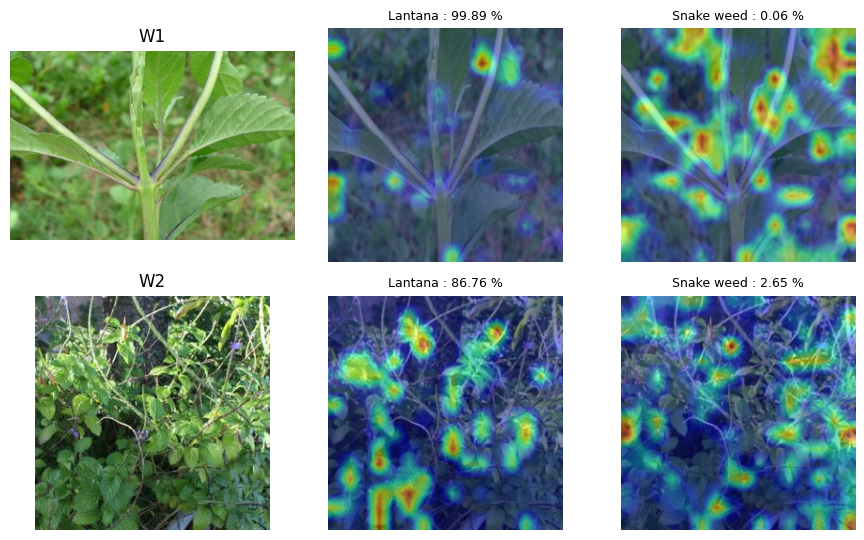

In [48]:
w2_image = Image.open(RESSOURCES / "w2.jpg").convert("RGB")
w1_image = Image.open(external_dir / "stachytarphetajamaicensis11.jpg").convert("RGB")
W, b = external_head.layers[-1].get_weights()
fig, axes = plt.subplots(2, 3, figsize=(9, 5.5))
for row, image in enumerate([w1_image, w2_image]):
    axes[row, 0].imshow(image); axes[row, 0].set_title(f"W{row + 1}")
    for col, target in enumerate([1, 2], 1):
        cam, probability = gradcam(image, target)
        axes[row, col].imshow(image.resize((224, 224), Image.Resampling.BILINEAR))
        axes[row, col].imshow(cam, cmap="jet", alpha=.45)
        axes[row, col].set_title(f"{CLASSES[target]} : {100*probability:.2f} %", fontsize=9)
        np.save(RESULTS / f"gradcam_w{row+1}_class{target}.npy", cam)
    for ax in axes[row]: ax.axis("off")
plt.tight_layout(); plt.show()

## 2.9. Temps d'inférence et taille
Mesure locale sur CPU, deux threads, batch 1, cinq échauffements puis trente appels. Le temps inclut JPEG en RAM, prétraitement et modèle ; il exclut réseau/HTTP/disque. Ce benchmark peut différer de celui du rapport.

In [49]:
dino_cpu = dino.to("cpu").eval()
payload = (RESSOURCES / "w2.jpg").read_bytes()
@torch.inference_mode()
def inference_benchmark():
    image = Image.open(io.BytesIO(payload)).convert("RGB")
    feature = dino_cpu(normal_transform(image).unsqueeze(0)).numpy()
    scaled = external_scaler.transform(feature)
    z = scaled @ W + b
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)
for _ in range(5): inference_benchmark()
latencies = []
for _ in range(30):
    started = time.perf_counter(); inference_benchmark()
    latencies.append(1000 * (time.perf_counter() - started))
benchmark = {"median_ms": float(np.median(latencies)), "p95_ms": float(np.percentile(latencies, 95)),
             "milliseconds": latencies, "threads": 2, "scope": "JPEG en RAM -> prétraitement -> DINOv2 -> scaler -> Softmax"}
ecrire_json(RESULTS / "benchmark.json", benchmark)
tableau([{"Médiane (ms)": benchmark["median_ms"], "p95 (ms)": benchmark["p95_ms"],
          "Poids DINOv2 (MiB)": DINO_WEIGHTS.stat().st_size / 2**20}]);

| Médiane (ms)   | p95 (ms)   | Poids DINOv2 (MiB)   |
|:---------------|:-----------|:---------------------|
| 138.94         | 164.37     | 84.19                |

## 2.10. Bilan : nouvelles mesures et références du rapport
Les références servent uniquement à afficher les écarts. Aucun score test ne choisit un modèle ou une seed.
Les différences de matériel, d'initialisation et de lots peuvent empêcher de retrouver exactement un ancien run.

In [50]:
final = []
for kind, ref in [("knn", 39.50), ("softmax", 45.16666666666667), ("cnn", 59.66666666666667)]:
    actual = 100 * np.mean([r[kind]["accuracy"] for r in core_results])
    final.append({"Étude": "900 / " + kind, "Mesure": "Moyenne CV", "Cette exécution (%)": actual,
                  "Rapport (%)": ref, "Écart (points)": actual - ref})
for protocol, kind, ref in [("random", "softmax", 92.46666666666667), ("date_grouped", "softmax", 83.96666666666667),
                             ("random", "knn", 91.46666666666667), ("date_grouped", "knn", 80.83333333333333)]:
    actual = 100 * oof_scores[protocol, kind]["accuracy"]
    final.append({"Étude": "DINO / " + kind, "Mesure": "OOF " + protocol, "Cette exécution (%)": actual,
                  "Rapport (%)": ref, "Écart (points)": actual - ref})
for label, actual, ref in [("DINO Softmax baseline", 100 * next(r for r in variant_results if r["id"] == BASELINE_EXPORT)["accuracy"], 92.5),
                            ("DINO Softmax externe", 100 * external_scores["accuracy"], 100*23/36)]:
    final.append({"Étude": label, "Mesure": "Accuracy", "Cette exécution (%)": actual,
                  "Rapport (%)": ref, "Écart (points)": actual - ref})
final_table = tableau(final)
final_table.to_csv(RESULTS / "bilan_rapport.csv", index=False)
ecrire_json(RESULTS / "all_results.json", RECORDS)
ecrire_json(EXPORT / "registry.json", REGISTRY)
ecrire_json(EXPORT / "recommended.json", recommended)
print("Modèles entraînés et sauvegardés :", len(REGISTRY))

| Étude                 | Mesure           | Cette exécution (%)   | Rapport (%)   | Écart (points)   |
|:----------------------|:-----------------|:----------------------|:--------------|:-----------------|
| 900 / knn             | Moyenne CV       | 39.50                 | 39.50         | 0.00             |
| 900 / softmax         | Moyenne CV       | 45.17                 | 45.17         | -0.00            |
| 900 / cnn             | Moyenne CV       | 58.61                 | 59.67         | -1.06            |
| DINO / softmax        | OOF random       | 92.47                 | 92.47         | 0.00             |
| DINO / softmax        | OOF date_grouped | 83.97                 | 83.97         | 0.00             |
| DINO / knn            | OOF random       | 91.47                 | 91.47         | 0.00             |
| DINO / knn            | OOF date_grouped | 80.83                 | 80.83         | 0.00             |
| DINO Softmax baseline | Accuracy         | 92.50                 | 92.50         | 0.00             |
| DINO Softmax externe  | Accuracy         | 63.89                 | 63.89         | 0.00             |

Modèles entraînés et sauvegardés : 84


# 3. Sauvegarde et téléchargement
Tous les modèles entraînés sont conservés avec leurs scalers, les labels et les extracteurs partagés.
Le fichier `inference.py` permet de recharger un modèle pour prédire une nouvelle image.

In [51]:
shutil.copy2("inference.py", EXPORT / "inference.py")
sys.path.insert(0, str(EXPORT))
from inference import Predictor

modele = Predictor(EXPORT, "dino_softmax_baseline")
probabilites_image = modele.predict_array(images[int(va[0])])
print("Classe prédite :", CLASSES[int(probabilites_image.argmax())])

Classe prédite : Chinee apple


### Télécharger l'archive des modèles

In [52]:
ecrire_json(EXPORT / "registry.json", REGISTRY)
ecrire_json(EXPORT / "recommended.json", recommended)
ecrire_json(EXPORT / "classes.json", CLASSES)
requirements = "\n".join(f"{p}=={metadata.version(p).split('+')[0]}" for p in paquets)
(EXPORT / "requirements.txt").write_text(requirements + "\njoblib\npandas\nmatplotlib\ntabulate\n")
archive_path = Path(shutil.make_archive(str(ROOT / "DeepWeeds_All_Models"), "zip", root_dir=EXPORT))
print("Modèles sauvegardés :", len(REGISTRY))
try:
    from google.colab import files
except ImportError:
    display(FileLink(str(archive_path.relative_to(Path.cwd()))))
else:
    files.download(str(archive_path))

Modèles sauvegardés : 84


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>